# BAYA — Online Handwritten Dataset Rescue + Balanced 63-Class v2

This notebook creates a **new, separate BAYA Dataset v2** without overwriting the original dataset.

## Goal

Build a balanced dataset with:

- **63 BAYA classes**
- **70 samples per class**
- **4,410 samples total**
- external/public handwritten samples used **first**
- original validated BAYA samples used only to fill classes or shortages that the public source cannot supply
- exact provenance recorded for every selected image
- optional EfficientNetB0 training section using the same 96×96 preprocessing as the current BAYA notebook

## Important research rule

This notebook does **not** pretend that public data matches BAYA automatically.

It will:

1. download/inspect external data;
2. map only labels that can be mapped to the canonical 63 BAYA labels;
3. show class coverage and shortages;
4. keep the original dataset untouched;
5. create a new balanced dataset;
6. explicitly mark every sample as `external_handwritten`, `external_optional`, or `original_baya`.

### Public sources supported

**Primary automatic source**

- `kmbandillo/baybayin-ocr-dataset` on GitHub
- handwritten character subset under `characters/hw`
- repository license: Apache-2.0
- README states that the handwritten character images originate from the Baybayin Character Dataset by Hammond, Vilvar, and Santos (2025)

**Optional source**

- Mark Jovic Daday, *Handwritten Baybayin Symbols Dataset*, Mendeley Data
- 36,000 handwritten symbols from 100 respondents
- CC BY 4.0
- primarily useful for traditional/basic Baybayin signs; do not assume it covers the full BAYA 63-class schema

The notebook never invents missing classes. If external data cannot provide a class, it reports the shortage and — if enabled — fills that class from your original validated BAYA dataset.

## 1 — Install/import libraries

Run this in Google Colab. TensorFlow is normally already available.

In [1]:
!pip -q install pillow pandas matplotlib scikit-learn scipy

import os
import re
import json
import math
import shutil
import hashlib
import random
import subprocess
import unicodedata
import zipfile

from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

try:
    import tensorflow as tf
    from tensorflow.keras import layers, Model
    print("TensorFlow:", tf.__version__)
except Exception as exc:
    tf = None
    print("TensorFlow import failed:", exc)

try:
    from google.colab import files
except Exception:
    files = None

print("Ready.")

TensorFlow: 2.21.0
Ready.


## 2 — Configuration

Recommended under time pressure:

- `EXTERNAL_FIRST = True`
- `TARGET_PER_CLASS = 70`
- `ALLOW_ORIGINAL_FALLBACK = True`

This means: use as many compatible public handwritten samples as possible, then use the original BAYA dataset only for shortages.

Set `RUN_TRAINING = False` if you only want the new dataset ZIP first.

In [2]:
# ============================================================
# CONFIGURATION
# ============================================================

TARGET_PER_CLASS = 70

# The dataset builder prioritizes external handwritten data.
EXTERNAL_FIRST = True

# If an online source does not cover a BAYA class or has <70 usable
# samples, fill the remaining slots with the original validated BAYA data.
ALLOW_ORIGINAL_FALLBACK = True

# If True, the builder refuses all original BAYA samples.
# This is expected to fail if public sources do not cover all 63 classes.
STRICT_EXTERNAL_ONLY = False

# Optional Mendeley ZIP support.
# Download "Baybayin Symbol Dataset.zip" manually from Mendeley Data
# and upload it in the optional section below.
USE_MENDELEY = False

# Keep automatic training off until the class audit looks correct.
RUN_TRAINING = True

# Training settings, used only if RUN_TRAINING=True.
IMG_HEIGHT = 96
IMG_WIDTH = 96
IMG_CHANNELS = 1

BATCH_SIZE = 32
EPOCHS = 30
WARMUP_EPOCHS = 5

LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 1e-5

IMAGE_PADDING_RATIO = 0.15
INK_THRESHOLD = 0.08

print("Target per class:", TARGET_PER_CLASS)
print("Target total:", TARGET_PER_CLASS * 63)
print("Original fallback:", ALLOW_ORIGINAL_FALLBACK)
print("Strict external only:", STRICT_EXTERNAL_ONLY)
print("Run training:", RUN_TRAINING)

Target per class: 70
Target total: 4410
Original fallback: True
Strict external only: False
Run training: True


## 3 — Canonical BAYA 63-class schema

This is the target schema. External labels are mapped **into this list only**.

In [3]:
# ============================================================
# CANONICAL BAYA 63 CLASSES
# ============================================================

VOWELS = [
    "a",
    "e_i",
    "o_u",
]

BASE_CONSONANTS = [
    "b",
    "d",
    "g",
    "h",
    "k",
    "l",
    "m",
    "n",
    "ng",
    "p",
    "r",
    "s",
    "t",
    "w",
    "y",
]

A_FORMS = [
    "ba",
    "da_ra",
    "ga",
    "ha",
    "ka",
    "la",
    "ma",
    "na",
    "nga",
    "pa",
    "ra",
    "sa",
    "ta",
    "wa",
    "ya",
]

EI_FORMS = [
    "be_bi",
    "de_di",
    "ge_gi",
    "he_hi",
    "ke_ki",
    "le_li",
    "me_mi",
    "ne_ni",
    "nge_ngi",
    "pe_pi",
    "re_ri",
    "se_si",
    "te_ti",
    "we_wi",
    "ye_yi",
]

OU_FORMS = [
    "bo_bu",
    "do_du",
    "go_gu",
    "ho_hu",
    "ko_ku",
    "lo_lu",
    "mo_mu",
    "no_nu",
    "ngo_ngu",
    "po_pu",
    "ro_ru",
    "so_su",
    "to_tu",
    "wo_wu",
    "yo_yu",
]

EXPECTED_LABELS = (
    VOWELS
    + BASE_CONSONANTS
    + A_FORMS
    + EI_FORMS
    + OU_FORMS
)

EXPECTED_LABEL_SET = set(EXPECTED_LABELS)

assert len(EXPECTED_LABELS) == 63
assert len(EXPECTED_LABEL_SET) == 63

print("Canonical classes:", len(EXPECTED_LABELS))
print(EXPECTED_LABELS)

Canonical classes: 63
['a', 'e_i', 'o_u', 'b', 'd', 'g', 'h', 'k', 'l', 'm', 'n', 'ng', 'p', 'r', 's', 't', 'w', 'y', 'ba', 'da_ra', 'ga', 'ha', 'ka', 'la', 'ma', 'na', 'nga', 'pa', 'ra', 'sa', 'ta', 'wa', 'ya', 'be_bi', 'de_di', 'ge_gi', 'he_hi', 'ke_ki', 'le_li', 'me_mi', 'ne_ni', 'nge_ngi', 'pe_pi', 're_ri', 'se_si', 'te_ti', 'we_wi', 'ye_yi', 'bo_bu', 'do_du', 'go_gu', 'ho_hu', 'ko_ku', 'lo_lu', 'mo_mu', 'no_nu', 'ngo_ngu', 'po_pu', 'ro_ru', 'so_su', 'to_tu', 'wo_wu', 'yo_yu']


## 4 — Workspace

Nothing here modifies your original ZIP. All new files are created under `/content/baya_dataset_rescue_v2`.

In [4]:
WORK_DIR = Path("/content/baya_dataset_rescue_v2")
EXTERNAL_DIR = WORK_DIR / "external"
ORIGINAL_DIR = WORK_DIR / "original_baya"
BUILD_DIR = WORK_DIR / "BAYA_DATASET_V2_70_PER_CLASS"
OUTPUT_DIR = WORK_DIR / "outputs"

for p in [EXTERNAL_DIR, ORIGINAL_DIR, BUILD_DIR, OUTPUT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("Workspace:", WORK_DIR)

Workspace: /content/baya_dataset_rescue_v2


# PART A — ONLINE DATA

## 5 — Download the GitHub Baybayin OCR dataset

This clones only a public repository. The notebook will use the `characters/hw` handwritten subset and will ignore synthetic font folders for the main external-handwriting pool.

In [5]:
GITHUB_REPO_URL = "https://github.com/kmbandillo/baybayin-ocr-dataset.git"
GITHUB_REPO_DIR = EXTERNAL_DIR / "baybayin-ocr-dataset"

if not GITHUB_REPO_DIR.exists():
    print("Cloning public dataset repository...")
    subprocess.run(
        [
            "git",
            "clone",
            "--depth",
            "1",
            GITHUB_REPO_URL,
            str(GITHUB_REPO_DIR),
        ],
        check=True,
    )
else:
    print("Repository already exists:", GITHUB_REPO_DIR)

print("Repository:", GITHUB_REPO_DIR)

Cloning public dataset repository...
Repository: /content/baya_dataset_rescue_v2/external/baybayin-ocr-dataset


## 6 — Label normalization

The external OCR repository may store labels either as Latin transliterations or as Unicode Baybayin/Tagalog characters.

The mapping below supports both. It does **not** map unknown labels automatically.

For standard Unicode:

- no vowel mark on a consonant → A-form (`ka`, `ba`, ...)
- upper E/I kudlit → E/I form (`ke_ki`, ...)
- lower O/U kudlit → O/U form (`ko_ku`, ...)
- virama/pamudpod → bare consonant (`k`, `b`, ...)

`DA` is mapped to BAYA's validated `da_ra` class. A separate Unicode RA, when present, maps to the R family.

In [6]:
# ============================================================
# EXTERNAL LABEL NORMALIZATION
# ============================================================

# Tagalog / Baybayin Unicode characters.
UNICODE_VOWELS = {
    "\u1700": "a",    # A
    "\u1701": "e_i",  # I/E
    "\u1702": "o_u",  # U/O
}

UNICODE_CONSONANTS = {
    "\u1703": "k",
    "\u1704": "g",
    "\u1705": "ng",
    "\u1706": "t",
    "\u1707": "d",
    "\u1708": "n",
    "\u1709": "p",
    "\u170A": "b",
    "\u170B": "m",
    "\u170C": "y",
    "\u170D": "r",
    "\u170E": "l",
    "\u170F": "w",
    "\u1710": "s",
    "\u1711": "h",
}

KUDLIT_EI = "\u1712"
KUDLIT_OU = "\u1713"
VIRAMAS = {"\u1714", "\u1715"}

def canonical_a_form(root):
    if root == "d":
        return "da_ra"
    if root == "r":
        return "ra"
    if root == "ng":
        return "nga"
    return root + "a"

def canonical_ei_form(root):
    if root == "d":
        return "de_di"
    if root == "r":
        return "re_ri"
    if root == "ng":
        return "nge_ngi"
    return f"{root}e_{root}i"

def canonical_ou_form(root):
    if root == "d":
        return "do_du"
    if root == "r":
        return "ro_ru"
    if root == "ng":
        return "ngo_ngu"
    return f"{root}o_{root}u"

def normalize_latin_label(raw):
    if raw is None:
        return None

    s = unicodedata.normalize("NFKC", str(raw)).strip().lower()

    # Common formatting normalization.
    s = s.replace("\\", "/")
    s = s.replace("-", "_")
    s = s.replace(" ", "")
    s = s.replace("/", "_")

    aliases = {
        "i_e": "e_i",
        "e_i": "e_i",
        "i": "e_i",
        "e": "e_i",
        "u_o": "o_u",
        "o_u": "o_u",
        "u": "o_u",
        "o": "o_u",

        "dara": "da_ra",
        "da_ra": "da_ra",
        "d_ra": "da_ra",
        "dara": "da_ra",

        "bebi": "be_bi",
        "dedi": "de_di",
        "gegi": "ge_gi",
        "hehi": "he_hi",
        "keki": "ke_ki",
        "leli": "le_li",
        "memi": "me_mi",
        "neni": "ne_ni",
        "ngengi": "nge_ngi",
        "pepi": "pe_pi",
        "reri": "re_ri",
        "sesi": "se_si",
        "teti": "te_ti",
        "wewi": "we_wi",
        "yeyi": "ye_yi",

        "bobu": "bo_bu",
        "dodu": "do_du",
        "gogu": "go_gu",
        "hohu": "ho_hu",
        "koku": "ko_ku",
        "lolu": "lo_lu",
        "momu": "mo_mu",
        "nonu": "no_nu",
        "ngongu": "ngo_ngu",
        "popu": "po_pu",
        "roru": "ro_ru",
        "sosu": "so_su",
        "totu": "to_tu",
        "wowu": "wo_wu",
        "yoyu": "yo_yu",
    }

    if s in EXPECTED_LABEL_SET:
        return s

    compact = s.replace("_", "")
    if compact in aliases:
        return aliases[compact]

    if s in aliases:
        return aliases[s]

    return None

def normalize_unicode_baybayin(raw):
    if raw is None:
        return None

    s = unicodedata.normalize("NFD", str(raw)).strip()

    # Remove normal whitespace only.
    s = "".join(ch for ch in s if not ch.isspace())

    if s in UNICODE_VOWELS:
        return UNICODE_VOWELS[s]

    if not s:
        return None

    base = s[0]
    if base not in UNICODE_CONSONANTS:
        return None

    root = UNICODE_CONSONANTS[base]
    marks = set(s[1:])

    if KUDLIT_EI in marks:
        return canonical_ei_form(root)

    if KUDLIT_OU in marks:
        return canonical_ou_form(root)

    if marks.intersection(VIRAMAS):
        return root

    if len(s) == 1:
        return canonical_a_form(root)

    return None

def normalize_external_label(raw):
    # First allow already-canonical / Latin transliteration.
    latin = normalize_latin_label(raw)
    if latin is not None:
        return latin

    # Then try Baybayin Unicode.
    return normalize_unicode_baybayin(raw)

# Quick self-checks.
examples = [
    "ka",
    "ke/ki",
    "ko-ku",
    "\u1703",
    "\u1703\u1712",
    "\u1703\u1713",
    "\u1703\u1714",
]

for x in examples:
    print(repr(x), "->", normalize_external_label(x))

'ka' -> ka
'ke/ki' -> ke_ki
'ko-ku' -> ko_ku
'ᜃ' -> ka
'ᜃᜒ' -> ke_ki
'ᜃᜓ' -> ko_ku
'ᜃ᜔' -> k


## 7 — Parse the GitHub handwritten character subset

The parser pairs `.gt.txt` files with neighboring image files when available. It also falls back to folder/filename labels if needed.

After this cell, inspect the **unmapped labels**. Do not proceed blindly if many samples are unmapped.

In [7]:
# ============================================================
# PARSE GITHUB HANDWRITTEN SUBSET — FIXED
# ============================================================

HW_DIR_CANDIDATES = [
    GITHUB_REPO_DIR / "characters" / "hw_characters",
    GITHUB_REPO_DIR / "characters" / "hw",
    GITHUB_REPO_DIR / "dataset" / "characters" / "hw_characters",
    GITHUB_REPO_DIR / "dataset" / "characters" / "hw",
]

HW_DIR = next(
    (p for p in HW_DIR_CANDIDATES if p.exists()),
    None
)

# Fallback: search for likely handwritten-character folders.
if HW_DIR is None:
    matches = [
        p
        for p in GITHUB_REPO_DIR.rglob("*")
        if (
            p.is_dir()
            and "character" in p.name.lower()
            and "hw" in p.name.lower()
        )
    ]

    if matches:
        HW_DIR = matches[0]

if HW_DIR is None:
    print("\nRepository contents:")
    for p in sorted(GITHUB_REPO_DIR.rglob("*")):
        if p.is_dir():
            print(p.relative_to(GITHUB_REPO_DIR))

    raise FileNotFoundError(
        "Could not locate the handwritten character directory."
    )

print("Handwritten source directory:")
print(HW_DIR)


IMAGE_EXTS = [
    ".tif",
    ".tiff",
    ".png",
    ".jpg",
    ".jpeg",
    ".bmp",
]


def find_companion_image(gt_path):
    """
    Find the image belonging to a .gt.txt transcription file.
    """

    name = gt_path.name

    if name.endswith(".gt.txt"):
        stem = name[:-7]
    else:
        stem = gt_path.stem

    # Exact filename match first.
    for ext in IMAGE_EXTS:
        candidate = gt_path.parent / f"{stem}{ext}"

        if candidate.exists():
            return candidate

    # Flexible fallback.
    for candidate in gt_path.parent.glob(stem + ".*"):

        if (
            candidate.is_file()
            and candidate.suffix.lower()
            in IMAGE_EXTS
        ):
            return candidate

    return None


github_records = []

# ------------------------------------------------------------
# METHOD 1:
# Tesseract .gt.txt + companion image
# ------------------------------------------------------------

gt_files = sorted(
    HW_DIR.rglob("*.gt.txt")
)

print(
    "Ground-truth files found:",
    len(gt_files)
)


for gt_path in gt_files:

    raw_label = (
        gt_path
        .read_text(
            encoding="utf-8",
            errors="ignore"
        )
        .strip()
    )

    image_path = (
        find_companion_image(
            gt_path
        )
    )

    if image_path is None:
        continue

    mapped = (
        normalize_external_label(
            raw_label
        )
    )

    github_records.append({
        "source":
            "github_kmbandillo_hw",

        "source_type":
            "external_handwritten",

        "license":
            "Apache-2.0 / underlying handwritten source per repository attribution",

        "raw_label":
            raw_label,

        "label":
            mapped,

        "image_path":
            str(image_path),

        "source_group":
            gt_path.parent.name,

        "source_id":
            gt_path
            .relative_to(HW_DIR)
            .as_posix(),
    })


# ------------------------------------------------------------
# METHOD 2:
# If .gt.txt pairing produced nothing,
# inspect image folders / filenames.
# ------------------------------------------------------------

if not github_records:

    print(
        "No usable .gt.txt/image pairs found."
    )

    print(
        "Trying image-folder / filename labels..."
    )

    image_files = [
        p
        for p in HW_DIR.rglob("*")
        if (
            p.is_file()
            and p.suffix.lower()
            in IMAGE_EXTS
        )
    ]

    print(
        "Image files found:",
        len(image_files)
    )

    for image_path in sorted(
        image_files
    ):

        candidate_labels = [
            image_path.parent.name,
            image_path.stem,
        ]

        # Include grandparent name too.
        if (
            image_path.parent.parent
            != image_path.parent
        ):
            candidate_labels.append(
                image_path
                .parent
                .parent
                .name
            )

        mapped = None
        used_raw = None

        for raw in candidate_labels:

            mapped = (
                normalize_external_label(
                    raw
                )
            )

            if mapped is not None:

                used_raw = raw

                break

        github_records.append({
            "source":
                "github_kmbandillo_hw",

            "source_type":
                "external_handwritten",

            "license":
                "Apache-2.0 / underlying handwritten source per repository attribution",

            "raw_label":
                used_raw
                or image_path.parent.name,

            "label":
                mapped,

            "image_path":
                str(image_path),

            "source_group":
                image_path.parent.name,

            "source_id":
                image_path
                .relative_to(HW_DIR)
                .as_posix(),
        })


github_df = pd.DataFrame(
    github_records
)

print()
print(
    "Parsed external handwritten images:",
    len(github_df)
)


if len(github_df):

    mapped_count = int(
        github_df[
            "label"
        ]
        .notna()
        .sum()
    )

    unmapped_count = int(
        github_df[
            "label"
        ]
        .isna()
        .sum()
    )

    print(
        "Mapped to BAYA:",
        mapped_count
    )

    print(
        "Unmapped:",
        unmapped_count
    )


    print(
        "\nRaw-label inventory:"
    )

    display(
        github_df
        .groupby(
            [
                "raw_label",
                "label",
            ],
            dropna=False,
        )
        .size()
        .rename(
            "samples"
        )
        .reset_index()
        .sort_values(
            "samples",
            ascending=False,
        )
        .head(100)
    )


    print(
        "\nMapped BAYA class counts:"
    )

    display(
        github_df
        .dropna(
            subset=[
                "label"
            ]
        )[
            "label"
        ]
        .value_counts()
        .reindex(
            EXPECTED_LABELS,
            fill_value=0,
        )
        .rename(
            "external_samples"
        )
        .to_frame()
    )

else:

    print(
        "No handwritten samples parsed."
    )

Handwritten source directory:
/content/baya_dataset_rescue_v2/external/baybayin-ocr-dataset/characters/hw_characters
Ground-truth files found: 29500

Parsed external handwritten images: 29500
Mapped to BAYA: 29500
Unmapped: 0

Raw-label inventory:


,raw_label,label,samples
35,ᜋ,ma,673
1,ᜁ,e_i,500
0,ᜀ,a,500
3,ᜃ,ka,500
4,ᜃᜒ,ke_ki,500
5,ᜃᜓ,ko_ku,500
6,ᜃ᜔,k,500
7,ᜄ,ga,500
8,ᜄᜒ,ge_gi,500
9,ᜄᜓ,go_gu,500



Mapped BAYA class counts:


,external_samples
label,
a,500
e_i,500
o_u,500
b,500
d,500
...,...
ro_ru,0
so_su,500
to_tu,500


## 8 — Optional Mendeley dataset upload

This is optional.

If you want to use it:

1. download **Baybayin Symbol Dataset.zip** from the Mendeley Data page;
2. set `USE_MENDELEY = True`;
3. run this cell and upload that ZIP.

Because external archive layouts can change, this parser is intentionally conservative. It maps a sample only when a folder or filename can be normalized to a BAYA class. Unmapped files stay unmapped instead of being guessed.

In [8]:
mendeley_df = pd.DataFrame(
    columns=[
        "source", "source_type", "license", "raw_label",
        "label", "image_path", "source_group", "source_id"
    ]
)

if USE_MENDELEY:
    if files is None:
        raise RuntimeError("Mendeley upload cell is designed for Google Colab.")

    print("Upload 'Baybayin Symbol Dataset.zip' from Mendeley Data.")
    uploaded = files.upload()

    zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
    if len(zip_names) != 1:
        raise ValueError("Upload exactly one Mendeley dataset ZIP.")

    m_zip = EXTERNAL_DIR / Path(zip_names[0]).name
    m_zip.write_bytes(uploaded[zip_names[0]])

    m_dir = EXTERNAL_DIR / "mendeley_baybayin"
    if m_dir.exists():
        shutil.rmtree(m_dir)
    m_dir.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(m_zip, "r") as zf:
        zf.extractall(m_dir)

    m_records = []

    for image_path in sorted(m_dir.rglob("*")):
        if not image_path.is_file() or image_path.suffix.lower() not in IMAGE_EXTS:
            continue

        candidates = [
            image_path.parent.name,
            image_path.parent.parent.name if image_path.parent.parent else "",
            image_path.stem,
        ]

        mapped = None
        raw_used = None

        for raw in candidates:
            mapped = normalize_external_label(raw)
            if mapped is not None:
                raw_used = raw
                break

        m_records.append({
            "source": "mendeley_daday_2020",
            "source_type": "external_handwritten",
            "license": "CC BY 4.0",
            "raw_label": raw_used or image_path.parent.name,
            "label": mapped,
            "image_path": str(image_path),
            "source_group": image_path.parent.name,
            "source_id": image_path.relative_to(m_dir).as_posix(),
        })

    mendeley_df = pd.DataFrame(m_records)

    print("Mendeley image files:", len(mendeley_df))
    print("Mapped:", int(mendeley_df["label"].notna().sum()))
    print("Unmapped:", int(mendeley_df["label"].isna().sum()))

    display(
        mendeley_df.groupby(["raw_label", "label"], dropna=False)
        .size()
        .rename("samples")
        .reset_index()
        .sort_values("samples", ascending=False)
        .head(100)
    )
else:
    print("USE_MENDELEY=False — skipped.")

USE_MENDELEY=False — skipped.


# PART B — ORIGINAL BAYA FALLBACK

## 9 — Upload your original `BAYA_DATASETS.zip`

This is used only to fill shortages, especially classes public sources may not contain (for example the R family).

If `STRICT_EXTERNAL_ONLY=True`, you can skip this section — but the build may fail if public data does not cover all 63 classes.

In [9]:
original_df = pd.DataFrame(
    columns=[
        "source", "source_type", "license", "raw_label",
        "label", "image_path", "source_group", "source_id"
    ]
)

if ALLOW_ORIGINAL_FALLBACK and not STRICT_EXTERNAL_ONLY:
    if files is None:
        raise RuntimeError("Original BAYA upload cell is designed for Google Colab.")

    print("Upload your ORIGINAL BAYA_DATASETS.zip.")
    uploaded = files.upload()

    zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
    if len(zip_names) != 1:
        raise ValueError("Upload exactly one outer ZIP: BAYA_DATASETS.zip.")

    outer_zip = ORIGINAL_DIR / Path(zip_names[0]).name
    outer_zip.write_bytes(uploaded[zip_names[0]])

    outer_extract = ORIGINAL_DIR / "outer"
    export_extract = ORIGINAL_DIR / "exports"

    for folder in [outer_extract, export_extract]:
        if folder.exists():
            shutil.rmtree(folder)
        folder.mkdir(parents=True, exist_ok=True)

    def safe_extract_zip(zip_path: Path, destination: Path):
        destination.mkdir(parents=True, exist_ok=True)
        destination_resolved = destination.resolve()

        with zipfile.ZipFile(zip_path, "r") as zf:
            for member in zf.infolist():
                target = (destination / member.filename).resolve()
                if destination_resolved not in target.parents and target != destination_resolved:
                    raise ValueError(f"Unsafe ZIP path: {member.filename}")
            zf.extractall(destination)

    safe_extract_zip(outer_zip, outer_extract)

    inner_zips = sorted(outer_extract.rglob("*.zip"))

    if not inner_zips:
        raise FileNotFoundError("No inner BAYA export ZIP files found.")

    for inner_zip in inner_zips:
        safe_extract_zip(inner_zip, export_extract / inner_zip.stem)

    o_records = []

    for export_folder in sorted(p for p in export_extract.iterdir() if p.is_dir()):
        for attempts_file in export_folder.rglob("attempts.json"):
            export_root = attempts_file.parent

            with open(attempts_file, "r", encoding="utf-8") as f:
                attempts = json.load(f)

            for rec in attempts:
                attempt_id = rec.get("attemptId")
                label = rec.get("targetClass")
                image_uri = rec.get("imageUri")

                if image_uri:
                    image_path = export_root / image_uri
                else:
                    image_path = export_root / "images" / f"attempt_{attempt_id}.png"

                canonical = str(label).strip() if label is not None else None
                if canonical not in EXPECTED_LABEL_SET:
                    canonical = normalize_external_label(canonical)

                o_records.append({
                    "source": "original_baya",
                    "source_type": "original_baya",
                    "license": "project-collected / validator-approved",
                    "raw_label": label,
                    "label": canonical,
                    "image_path": str(image_path),
                    "source_group": export_folder.name,
                    "source_id": f"{export_folder.name}/{attempt_id}",
                })

    original_df = pd.DataFrame(o_records)

    print("Original BAYA records:", len(original_df))
    print("Mapped classes:", original_df["label"].nunique())
    print("Missing images:", int((~original_df["image_path"].map(lambda p: Path(p).is_file())).sum()))

    display(
        original_df["label"]
        .value_counts()
        .reindex(EXPECTED_LABELS, fill_value=0)
        .rename("original_samples")
        .to_frame()
    )
else:
    print("Original fallback disabled.")

Upload your ORIGINAL BAYA_DATASETS.zip.


Saving BAYA_DATASETS.zip to BAYA_DATASETS.zip
Original BAYA records: 4410
Mapped classes: 63
Missing images: 0


,original_samples
label,
a,70
e_i,70
o_u,70
b,70
d,70
...,...
ro_ru,70
so_su,70
to_tu,70


# PART C — AUDIT BEFORE BUILDING

## 10 — Combine external sources and inspect 63-class coverage

Do **not** continue to the build if the counts or mappings look suspicious.

A public source having an image is not enough; the label must also make sense for BAYA's canonical class.

In [10]:
external_frames = []

if len(github_df):
    external_frames.append(github_df)

if len(mendeley_df):
    external_frames.append(mendeley_df)

if external_frames:
    external_df = pd.concat(external_frames, ignore_index=True)
else:
    external_df = pd.DataFrame(columns=original_df.columns)

mapped_external = external_df[
    external_df["label"].isin(EXPECTED_LABEL_SET)
].copy()

external_counts = (
    mapped_external["label"]
    .value_counts()
    .reindex(EXPECTED_LABELS, fill_value=0)
)

original_counts = (
    original_df["label"]
    .value_counts()
    .reindex(EXPECTED_LABELS, fill_value=0)
    if len(original_df)
    else pd.Series(0, index=EXPECTED_LABELS, dtype=int)
)

coverage = pd.DataFrame({
    "class": EXPECTED_LABELS,
    "external_available": [int(external_counts[x]) for x in EXPECTED_LABELS],
    "original_available": [int(original_counts[x]) for x in EXPECTED_LABELS],
})

coverage["external_shortage_to_70"] = np.maximum(
    0,
    TARGET_PER_CLASS - coverage["external_available"]
)

coverage["can_build_with_fallback"] = (
    coverage["external_available"] + coverage["original_available"]
    >= TARGET_PER_CLASS
)

display(coverage)

print("\nExternal coverage summary")
print("Classes with >=70 external:", int((coverage["external_available"] >= 70).sum()), "/ 63")
print("Classes with some external:", int((coverage["external_available"] > 0).sum()), "/ 63")
print("Classes with zero external:", int((coverage["external_available"] == 0).sum()), "/ 63")

zero_external = coverage[coverage["external_available"] == 0]["class"].tolist()
print("Zero-external classes:", zero_external)

cannot_build = coverage[~coverage["can_build_with_fallback"]]
if len(cannot_build):
    print("\nWARNING — not enough data to reach 70 for these classes:")
    display(cannot_build)
else:
    print("\n✓ Every class can reach 70 using external + allowed original fallback.")

,class,external_available,original_available,external_shortage_to_70,can_build_with_fallback
0,a,500,70,0,True
1,e_i,500,70,0,True
2,o_u,500,70,0,True
3,b,500,70,0,True
4,d,500,70,0,True
...,...,...,...,...,...
58,ro_ru,0,70,70,True
59,so_su,500,70,0,True
60,to_tu,500,70,0,True
61,wo_wu,500,70,0,True



External coverage summary
Classes with >=70 external: 59 / 63
Classes with some external: 59 / 63
Classes with zero external: 4 / 63
Zero-external classes: ['r', 'ra', 're_ri', 'ro_ru']

✓ Every class can reach 70 using external + allowed original fallback.


## 11 — Visual validation helper

Use this before building.

Examples:

```python
preview_external_class("ka", 12)
preview_external_class("ke_ki", 12)
preview_external_class("ko_ku", 12)
```

If a class looks mislabeled, stop and fix the mapping instead of training on it.

/tmp/ipykernel_932/1163241613.py:34: UserWarning: Glyph 5891 (\N{TAGALOG LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 5891 (\N{TAGALOG LETTER KA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


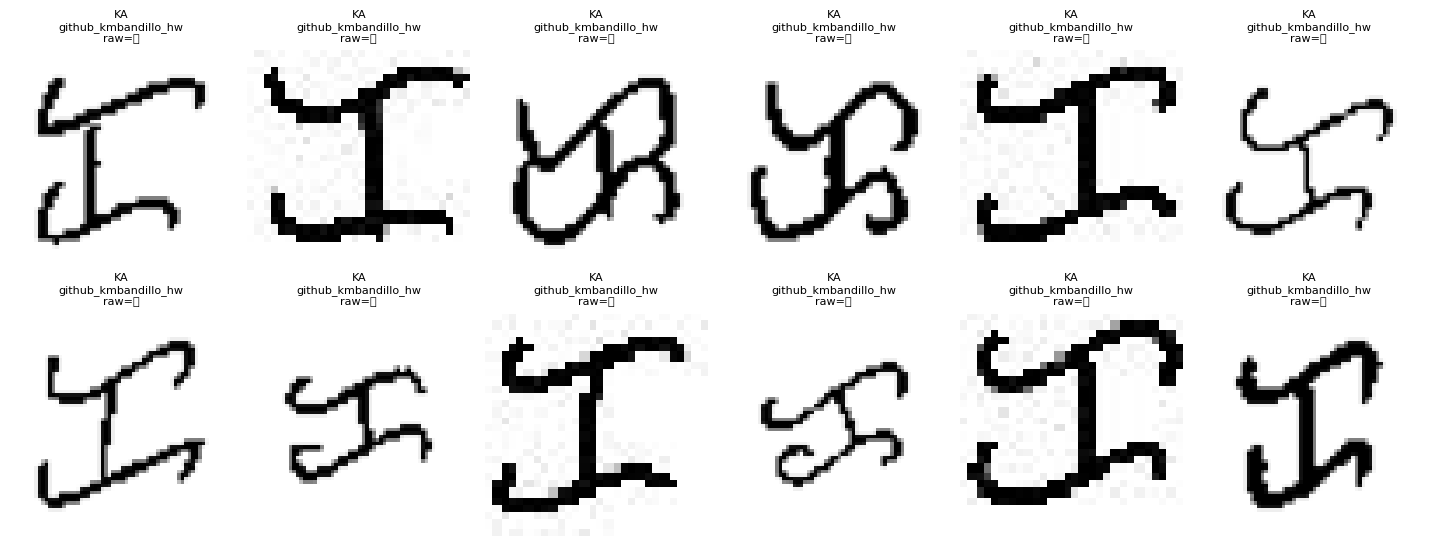

/tmp/ipykernel_932/1163241613.py:34: UserWarning: Glyph 5906 (\N{TAGALOG VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 5906 (\N{TAGALOG VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


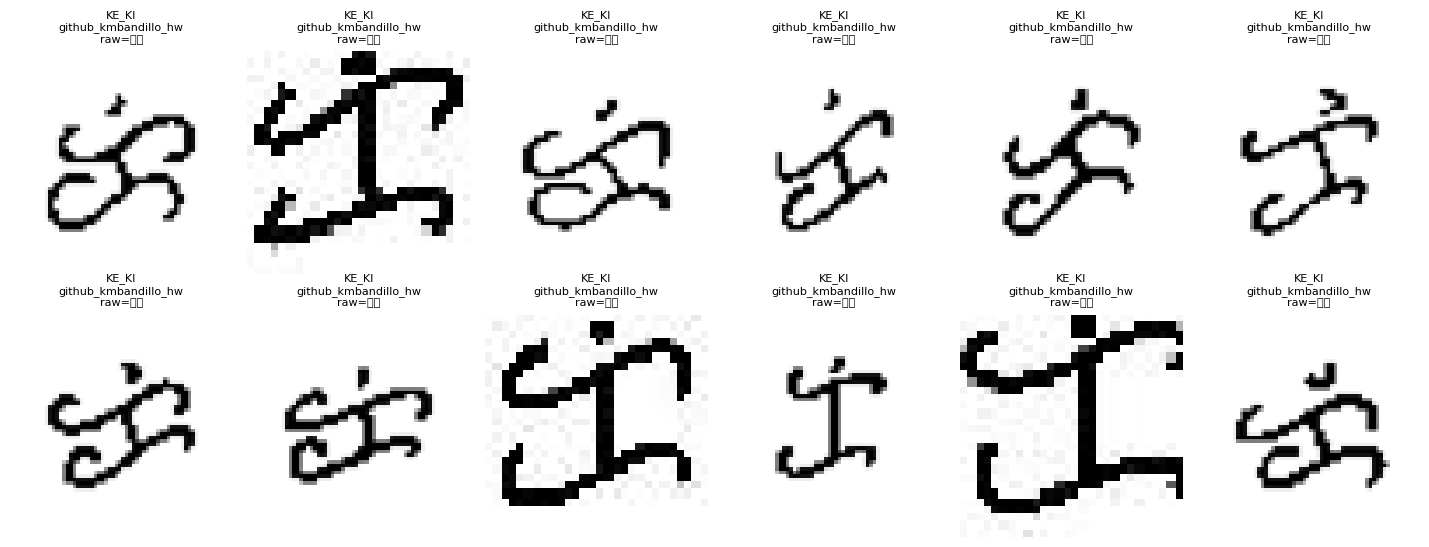

/tmp/ipykernel_932/1163241613.py:34: UserWarning: Glyph 5907 (\N{TAGALOG VOWEL SIGN U}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 5907 (\N{TAGALOG VOWEL SIGN U}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


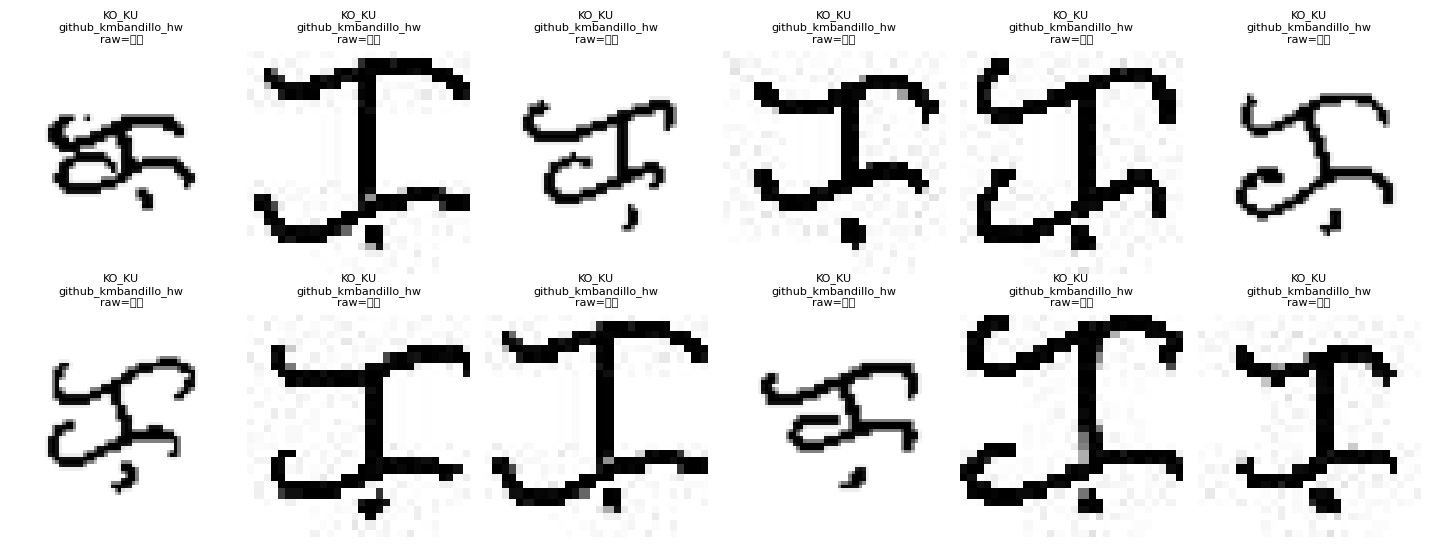

/tmp/ipykernel_932/1163241613.py:34: UserWarning: Glyph 5908 (\N{TAGALOG SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 5908 (\N{TAGALOG SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


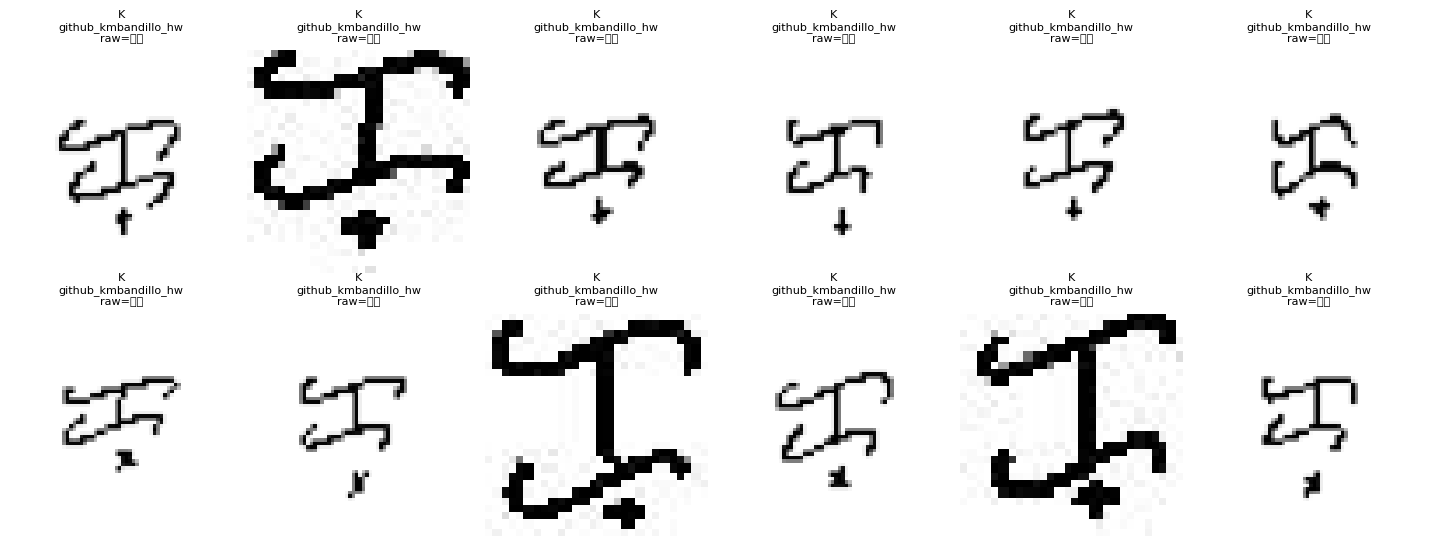

In [11]:
def show_image_any(path):
    img = Image.open(path).convert("RGBA")
    bg = Image.new("RGBA", img.size, (255, 255, 255, 255))
    bg.alpha_composite(img)
    return bg.convert("L")

def preview_external_class(label, n=12, seed=42):
    subset = mapped_external[mapped_external["label"] == label].copy()

    if subset.empty:
        print("No external samples for:", label)
        return

    subset = subset.sample(min(n, len(subset)), random_state=seed).reset_index(drop=True)

    cols = min(6, len(subset))
    rows = math.ceil(len(subset) / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.4, rows * 2.8), squeeze=False)
    axes = axes.reshape(-1)

    for i, ax in enumerate(axes):
        ax.axis("off")
        if i >= len(subset):
            continue

        row = subset.iloc[i]
        ax.imshow(show_image_any(row["image_path"]), cmap="gray")
        ax.set_title(
            f"{label.upper()}\n{row['source']}\nraw={row['raw_label']}",
            fontsize=8
        )

    plt.tight_layout()
    plt.show()

# Start with the family that exposed the current problem.
for label in ["ka", "ke_ki", "ko_ku", "k"]:
    preview_external_class(label, n=12)

# PART D — BUILD THE NEW 70/CLASS DATASET

## 12 — Hash and remove exact duplicates

This prevents selecting the exact same image twice when multiple public sources overlap.

In [12]:
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

all_candidate_frames = []

if len(mapped_external):
    all_candidate_frames.append(mapped_external.copy())

if len(original_df):
    all_candidate_frames.append(
        original_df[original_df["label"].isin(EXPECTED_LABEL_SET)].copy()
    )

candidates = pd.concat(all_candidate_frames, ignore_index=True)

print("Candidate rows before hashing:", len(candidates))

candidates["image_exists"] = candidates["image_path"].map(lambda p: Path(p).is_file())
candidates = candidates[candidates["image_exists"]].copy()

print("Hashing images...")
candidates["sha256"] = candidates["image_path"].map(sha256_file)

# Same bytes only need one provenance row.
duplicate_count = int(candidates.duplicated("sha256").sum())
print("Exact duplicate rows:", duplicate_count)

candidates = (
    candidates.sort_values(["source_type", "source", "source_id"])
    .drop_duplicates("sha256", keep="first")
    .reset_index(drop=True)
)

print("Unique candidate images:", len(candidates))

Candidate rows before hashing: 33910
Hashing images...
Exact duplicate rows: 10404
Unique candidate images: 23506


## 13 — External-first balanced selection

Rules:

- target exactly **70 images per class**;
- external handwritten samples are selected first;
- original BAYA fills only the remaining shortage;
- no class is oversampled by duplicating the same file;
- if a class still has fewer than 70 unique images, the notebook stops.

This does **not** generate fake kudlits or synthetic classes.

In [13]:
rng = np.random.default_rng(SEED)

selected_parts = []
selection_summary = []

for label in EXPECTED_LABELS:
    class_rows = candidates[candidates["label"] == label].copy()

    external_rows = class_rows[
        class_rows["source_type"].str.startswith("external", na=False)
    ].copy()

    original_rows = class_rows[
        class_rows["source_type"] == "original_baya"
    ].copy()

    # deterministic shuffle
    ext_idx = rng.permutation(len(external_rows)) if len(external_rows) else []
    orig_idx = rng.permutation(len(original_rows)) if len(original_rows) else []

    external_rows = external_rows.iloc[ext_idx].reset_index(drop=True) if len(external_rows) else external_rows
    original_rows = original_rows.iloc[orig_idx].reset_index(drop=True) if len(original_rows) else original_rows

    if STRICT_EXTERNAL_ONLY:
        take_external = min(TARGET_PER_CLASS, len(external_rows))
        chosen = external_rows.iloc[:take_external].copy()
    else:
        take_external = min(TARGET_PER_CLASS, len(external_rows))
        chosen_external = external_rows.iloc[:take_external].copy()

        remaining = TARGET_PER_CLASS - len(chosen_external)

        if remaining > 0 and ALLOW_ORIGINAL_FALLBACK:
            chosen_original = original_rows.iloc[:remaining].copy()
        else:
            chosen_original = original_rows.iloc[:0].copy()

        chosen = pd.concat([chosen_external, chosen_original], ignore_index=True)

    if len(chosen) < TARGET_PER_CLASS:
        raise ValueError(
            f"Class {label!r} has only {len(chosen)} usable unique samples; "
            f"need {TARGET_PER_CLASS}. External={len(external_rows)}, "
            f"original={len(original_rows)}."
        )

    chosen = chosen.iloc[:TARGET_PER_CLASS].copy()
    chosen["selection_rank"] = np.arange(1, len(chosen) + 1)

    selected_parts.append(chosen)

    selection_summary.append({
        "class": label,
        "selected_total": len(chosen),
        "external_selected": int(chosen["source_type"].str.startswith("external", na=False).sum()),
        "original_selected": int((chosen["source_type"] == "original_baya").sum()),
    })

selected_df = pd.concat(selected_parts, ignore_index=True)

summary_df = pd.DataFrame(selection_summary)

display(summary_df)

print("\nSelected total:", len(selected_df))
print("Expected total:", 63 * TARGET_PER_CLASS)

assert len(selected_df) == 63 * TARGET_PER_CLASS

class_counts = selected_df["label"].value_counts().reindex(EXPECTED_LABELS, fill_value=0)

assert (class_counts == TARGET_PER_CLASS).all()

print("✓ Exactly 70 unique selected images per class.")

,class,selected_total,external_selected,original_selected
0,a,70,70,0
1,e_i,70,70,0
2,o_u,70,70,0
3,b,70,70,0
4,d,70,70,0
...,...,...,...,...
58,ro_ru,70,0,70
59,so_su,70,70,0
60,to_tu,70,42,28
61,wo_wu,70,46,24



Selected total: 4410
Expected total: 4410
✓ Exactly 70 unique selected images per class.


## 14 — Materialize the new dataset as PNG files

The resulting folder structure is:

```text
BAYA_DATASET_V2_70_PER_CLASS/
  images/
    a/
    e_i/
    ...
    ka/
    ke_ki/
    ...
  manifest.csv
  provenance_summary.csv
  class_counts.csv
```

Every copied image is converted to PNG for a consistent training format. The original files stay untouched.

In [14]:
if BUILD_DIR.exists():
    shutil.rmtree(BUILD_DIR)

(BUILD_DIR / "images").mkdir(parents=True, exist_ok=True)

materialized_rows = []

for label in EXPECTED_LABELS:
    target_folder = BUILD_DIR / "images" / label
    target_folder.mkdir(parents=True, exist_ok=True)

    rows = selected_df[selected_df["label"] == label].reset_index(drop=True)

    for i, row in rows.iterrows():
        sample_id = f"{label}_{i+1:03d}"
        out_path = target_folder / f"{sample_id}.png"

        img = Image.open(row["image_path"]).convert("RGBA")
        bg = Image.new("RGBA", img.size, (255, 255, 255, 255))
        bg.alpha_composite(img)
        bg.convert("L").save(out_path)

        materialized_rows.append({
            "sample_id": sample_id,
            "label": label,
            "image_path": str(out_path),
            "source": row["source"],
            "source_type": row["source_type"],
            "license": row["license"],
            "raw_label": row["raw_label"],
            "source_group": row["source_group"],
            "source_id": row["source_id"],
            "source_sha256": row["sha256"],
        })

manifest_df = pd.DataFrame(materialized_rows)

manifest_df.to_csv(BUILD_DIR / "manifest.csv", index=False)
summary_df.to_csv(BUILD_DIR / "provenance_summary.csv", index=False)

(
    manifest_df["label"]
    .value_counts()
    .reindex(EXPECTED_LABELS, fill_value=0)
    .rename("samples")
    .to_frame()
    .to_csv(BUILD_DIR / "class_counts.csv")
)

print("Created:", BUILD_DIR)
print("Rows:", len(manifest_df))
print("Classes:", manifest_df["label"].nunique())

Created: /content/baya_dataset_rescue_v2/BAYA_DATASET_V2_70_PER_CLASS
Rows: 4410
Classes: 63


## 15 — Final structural + provenance audit

In [15]:
final_counts = (
    manifest_df["label"]
    .value_counts()
    .reindex(EXPECTED_LABELS, fill_value=0)
)

audit_df = pd.DataFrame({
    "class": EXPECTED_LABELS,
    "samples": [int(final_counts[x]) for x in EXPECTED_LABELS],
    "external": [
        int(
            (
                (manifest_df["label"] == x)
                & manifest_df["source_type"].str.startswith("external", na=False)
            ).sum()
        )
        for x in EXPECTED_LABELS
    ],
    "original_fallback": [
        int(
            (
                (manifest_df["label"] == x)
                & (manifest_df["source_type"] == "original_baya")
            ).sum()
        )
        for x in EXPECTED_LABELS
    ],
})

audit_df["status"] = np.where(audit_df["samples"] == TARGET_PER_CLASS, "OK", "CHECK")

display(audit_df)

print("\nTotal samples:", len(manifest_df))
print("Exact 70/class:", bool((audit_df["samples"] == TARGET_PER_CLASS).all()))
print("External samples:", int(manifest_df["source_type"].str.startswith("external", na=False).sum()))
print("Original fallback:", int((manifest_df["source_type"] == "original_baya").sum()))

if not (audit_df["samples"] == TARGET_PER_CLASS).all():
    raise AssertionError("Final dataset is not exactly balanced.")

print("✓ Balanced 63 × 70 = 4,410 dataset confirmed.")

,class,samples,external,original_fallback,status
0,a,70,70,0,OK
1,e_i,70,70,0,OK
2,o_u,70,70,0,OK
3,b,70,70,0,OK
4,d,70,70,0,OK
...,...,...,...,...,...
58,ro_ru,70,0,70,OK
59,so_su,70,70,0,OK
60,to_tu,70,42,28,OK
61,wo_wu,70,46,24,OK



Total samples: 4410
Exact 70/class: True
External samples: 3978
Original fallback: 432
✓ Balanced 63 × 70 = 4,410 dataset confirmed.


## 16 — Visual final audit

This is the most important human check before training.

The code below shows random samples from selected classes **after the final selection**.

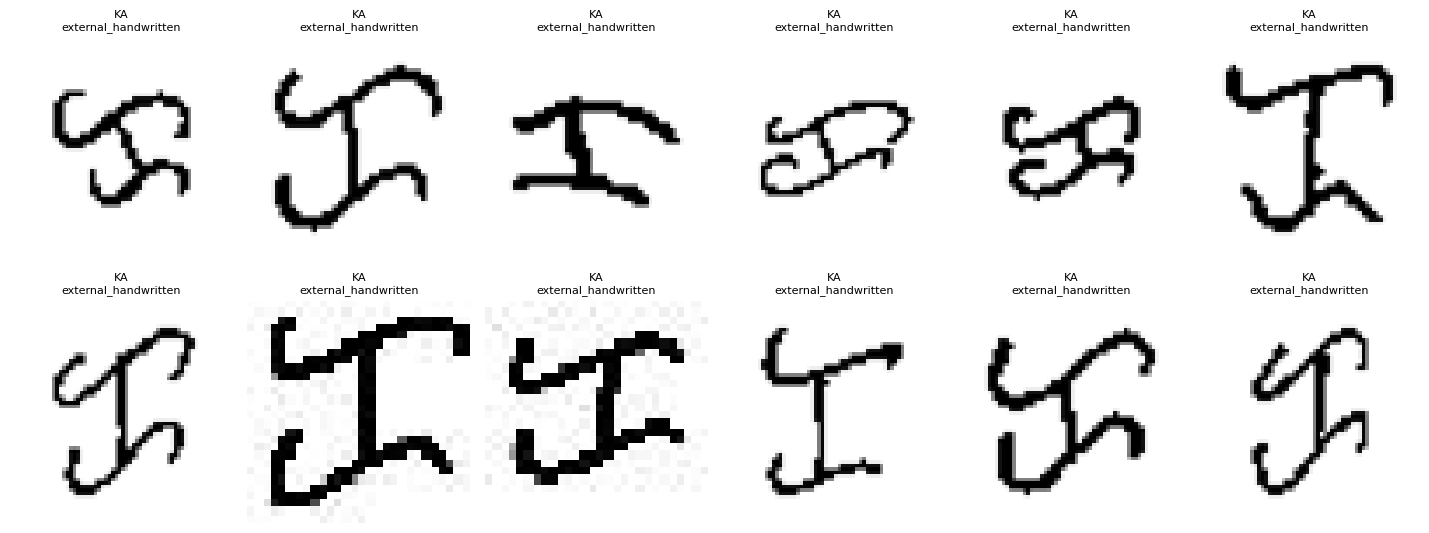

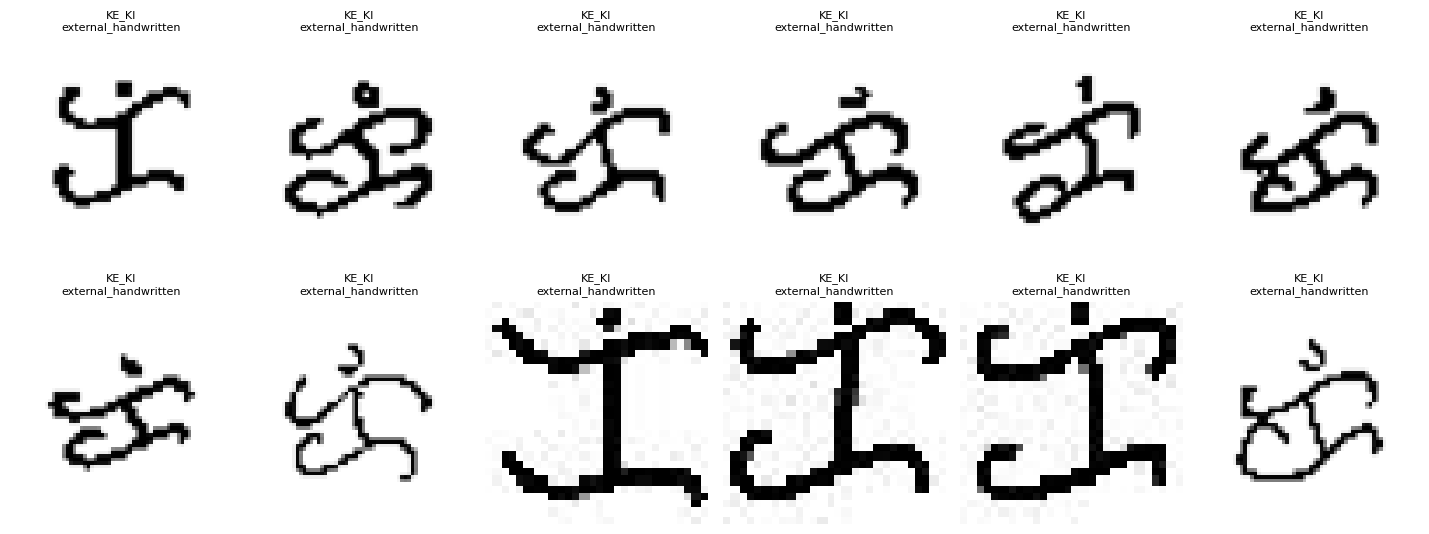

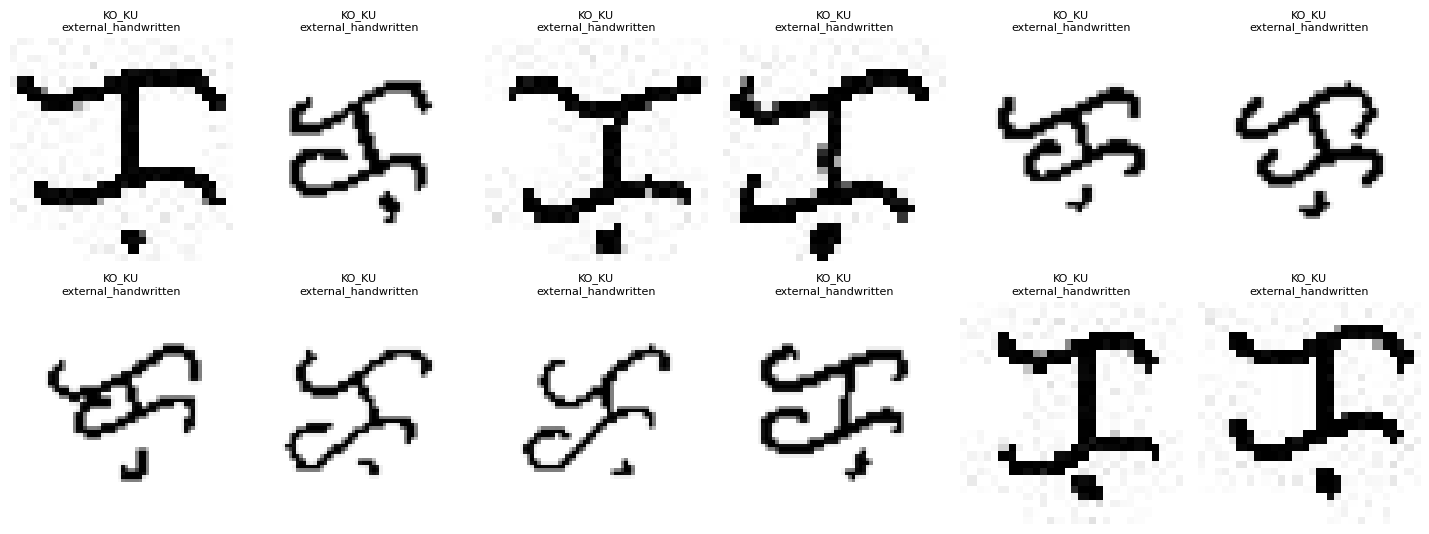

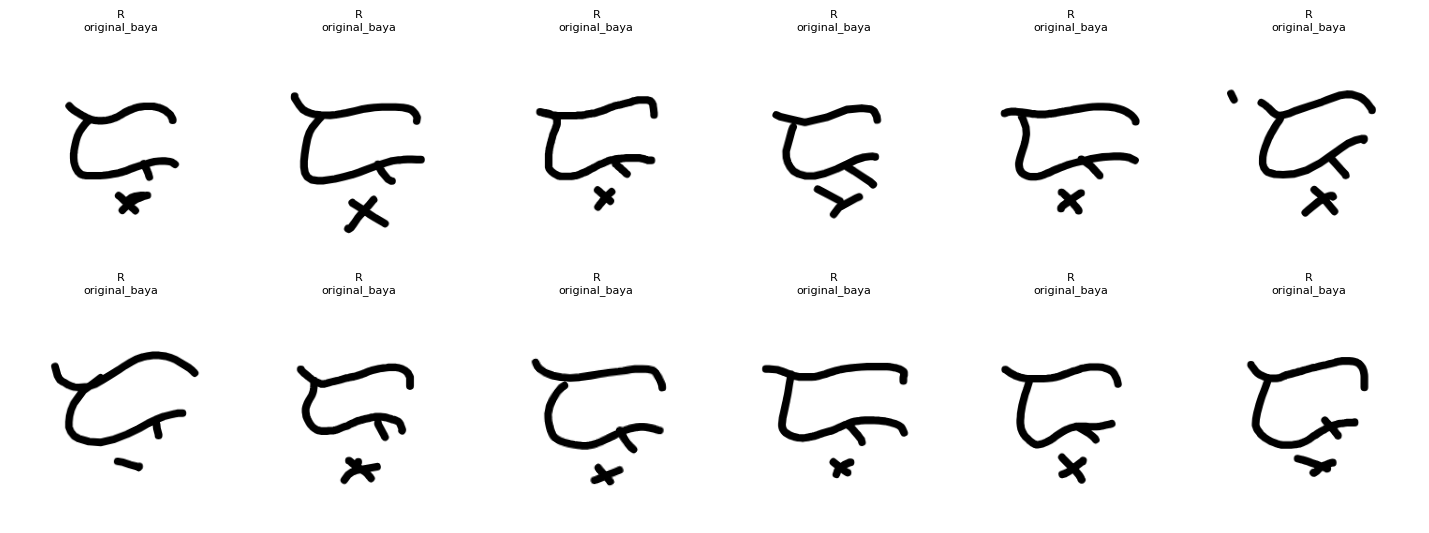

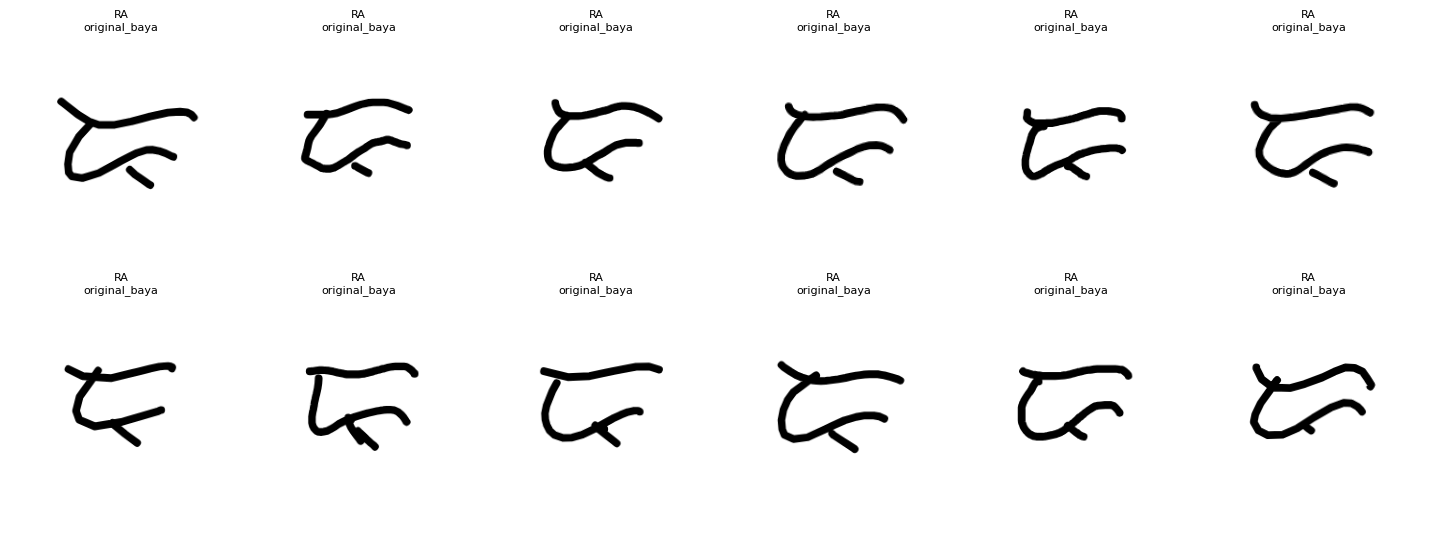

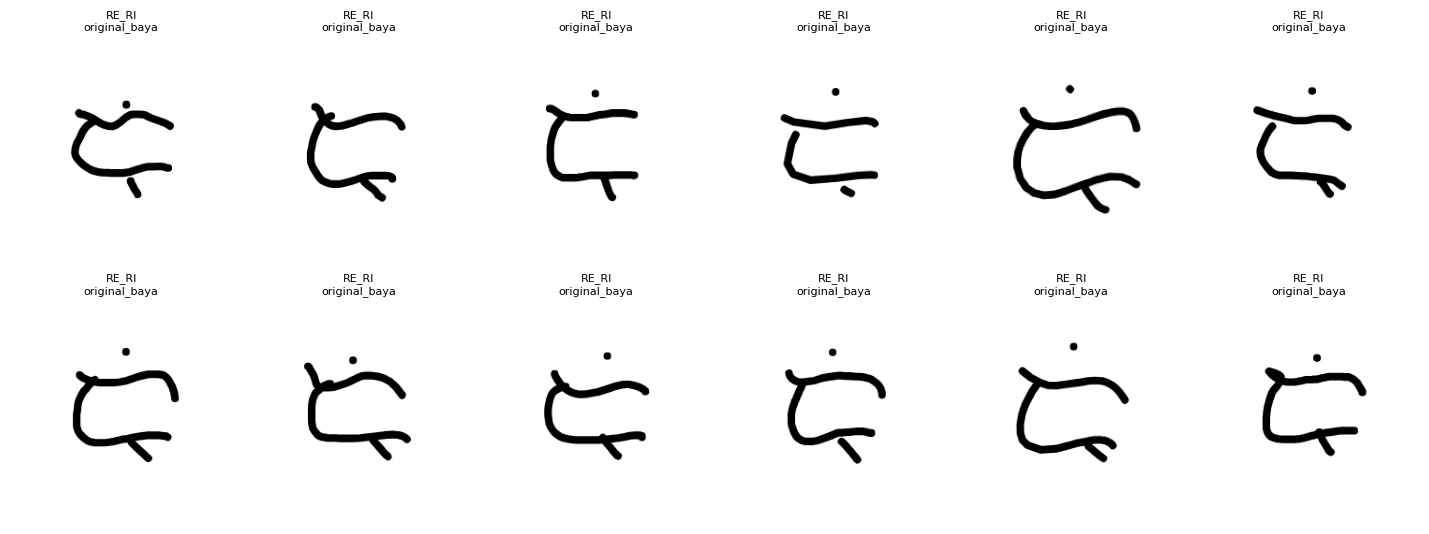

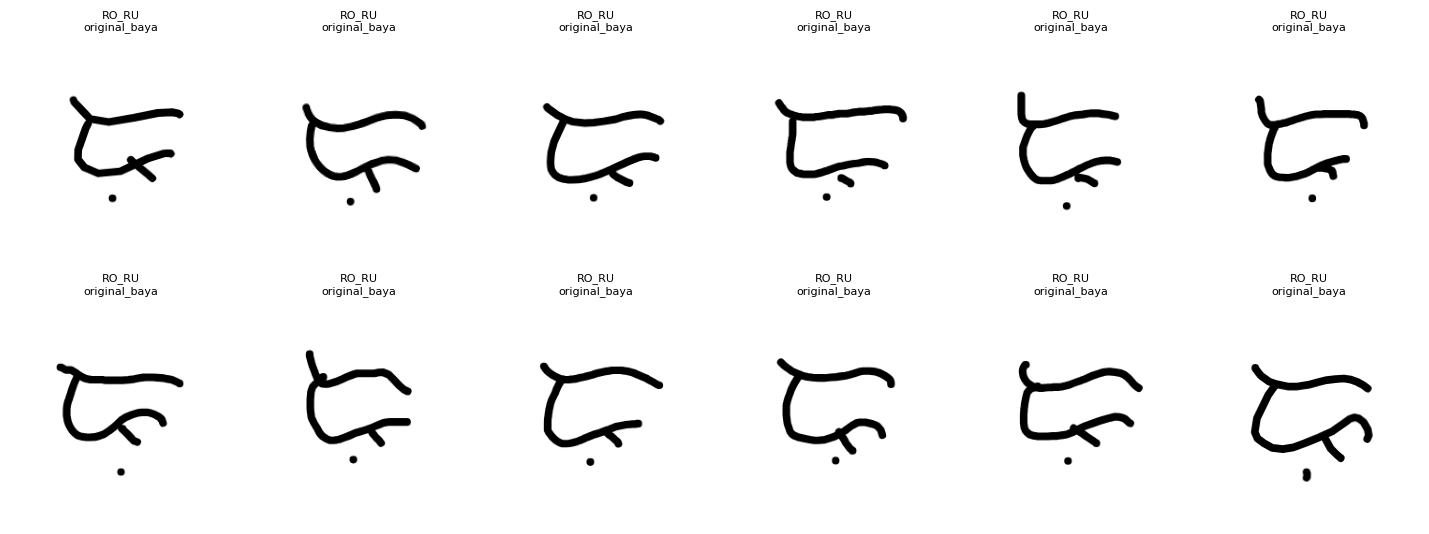

In [16]:
def preview_final_class(label, n=12, seed=42):
    subset = manifest_df[manifest_df["label"] == label].sample(
        min(n, TARGET_PER_CLASS),
        random_state=seed
    ).reset_index(drop=True)

    cols = min(6, len(subset))
    rows = math.ceil(len(subset) / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.4, rows * 2.8), squeeze=False)
    axes = axes.reshape(-1)

    for i, ax in enumerate(axes):
        ax.axis("off")
        if i >= len(subset):
            continue

        row = subset.iloc[i]
        ax.imshow(Image.open(row["image_path"]), cmap="gray")
        ax.set_title(
            f"{label.upper()}\n{row['source_type']}",
            fontsize=8
        )

    plt.tight_layout()
    plt.show()

for label in ["ka", "ke_ki", "ko_ku", "r", "ra", "re_ri", "ro_ru"]:
    preview_final_class(label, n=12)

## 17 — Create a fixed 50/10/10 per-class split

For a rapid rescue experiment, this creates:

- 50/class train = 3,150
- 10/class validation = 630
- 10/class test = 630

### Limitation

Unless a public dataset provides verified writer IDs, this split is **not claimed to be writer-disjoint**. The manifest retains source provenance so this limitation can be disclosed honestly.

This split is useful for a quick controlled experiment, not as proof of universal real-world accuracy.

In [17]:
split_rows = []

rng_split = np.random.default_rng(SEED)

for label in EXPECTED_LABELS:
    rows = manifest_df[manifest_df["label"] == label].copy().reset_index(drop=True)
    order = rng_split.permutation(len(rows))
    rows = rows.iloc[order].reset_index(drop=True)

    rows.loc[:49, "split"] = "train"
    rows.loc[50:59, "split"] = "validation"
    rows.loc[60:69, "split"] = "test"

    split_rows.append(rows)

split_df = pd.concat(split_rows, ignore_index=True)

split_df.to_csv(BUILD_DIR / "split_manifest.csv", index=False)

split_counts = pd.crosstab(split_df["label"], split_df["split"]).reindex(EXPECTED_LABELS)

display(split_counts)

assert (split_counts["train"] == 50).all()
assert (split_counts["validation"] == 10).all()
assert (split_counts["test"] == 10).all()

print("✓ 50/10/10 per class split created.")

split,test,train,validation
label,,,
a,10,50,10
e_i,10,50,10
o_u,10,50,10
b,10,50,10
d,10,50,10
...,...,...,...
ro_ru,10,50,10
so_su,10,50,10
to_tu,10,50,10


✓ 50/10/10 per class split created.


# PART E — OPTIONAL TRAINING

The cells below use the same core 96×96 image normalization as your current EfficientNetB0 notebook.

If `RUN_TRAINING=False`, you can skip directly to the export section.

In [18]:
def load_image_array(image_path):
    img = Image.open(image_path).convert("RGBA")
    bg = Image.new("RGBA", img.size, (255, 255, 255, 255))
    bg.alpha_composite(img)

    gray = bg.convert("L")
    arr = np.asarray(gray, dtype=np.float32) / 255.0

    # white -> 0, black ink -> 1
    ink = 1.0 - arr

    mask = ink > INK_THRESHOLD

    if np.any(mask):
        ys, xs = np.where(mask)
        y0, y1 = int(ys.min()), int(ys.max()) + 1
        x0, x1 = int(xs.min()), int(xs.max()) + 1

        crop = ink[y0:y1, x0:x1]

        crop_h, crop_w = crop.shape
        max_dim = max(crop_h, crop_w)

        padding = max(2, int(round(max_dim * IMAGE_PADDING_RATIO)))
        square_side = max_dim + 2 * padding

        square = np.zeros((square_side, square_side), dtype=np.float32)

        top = (square_side - crop_h) // 2
        left = (square_side - crop_w) // 2

        square[top:top + crop_h, left:left + crop_w] = crop
    else:
        square = ink

    square_u8 = np.clip(square * 255.0, 0, 255).astype(np.uint8)

    standardized = Image.fromarray(square_u8, mode="L").resize(
        (IMG_WIDTH, IMG_HEIGHT),
        Image.Resampling.BILINEAR,
    )

    result = np.asarray(standardized, dtype=np.float32) / 255.0

    return result[..., None].astype(np.float32)

label_to_id = {label: i for i, label in enumerate(sorted(EXPECTED_LABELS))}
id_to_label = {i: label for label, i in label_to_id.items()}
NUM_CLASSES = len(label_to_id)

print("Class count:", NUM_CLASSES)
print("KA family:", {x: label_to_id[x] for x in ["ka", "ke_ki", "ko_ku"]})

Class count: 63
KA family: {'ka': 19, 'ke_ki': 20, 'ko_ku': 21}


In [19]:
if RUN_TRAINING:
    def split_to_arrays(name):
        part = split_df[split_df["split"] == name].reset_index(drop=True)

        X = np.stack(
            [load_image_array(p) for p in part["image_path"]],
            axis=0
        ).astype(np.float32)

        y = np.asarray(
            [label_to_id[x] for x in part["label"]],
            dtype=np.int32
        )

        return part, X, y

    train_df, X_train, y_train = split_to_arrays("train")
    val_df, X_val, y_val = split_to_arrays("validation")
    test_df, X_test, y_test = split_to_arrays("test")

    print("Train:", X_train.shape, y_train.shape)
    print("Validation:", X_val.shape, y_val.shape)
    print("Test:", X_test.shape, y_test.shape)
else:
    print("RUN_TRAINING=False — tensor conversion skipped.")

/tmp/ipykernel_932/3355527788.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  standardized = Image.fromarray(square_u8, mode="L").resize(


Train: (3150, 96, 96, 1) (3150,)
Validation: (630, 96, 96, 1) (630,)
Test: (630, 96, 96, 1) (630,)


## 18 — EfficientNetB0 model

This follows the same image-only idea as your current notebook:

- public input: `(96,96,1)`
- grayscale repeated to RGB
- convert ink representation back to 0–255 RGB
- ImageNet EfficientNetB0 backbone
- Dense 128
- Dropout 0.40
- 63-way softmax

In [20]:
if RUN_TRAINING:
    from tensorflow.keras import layers, Model

    def compile_classifier(model, lr):
        model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=lr,
                clipnorm=1.0
            ),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
        )

    def build_model():
        image_input = layers.Input(
            shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS),
            name="image_input"
        )

        rgb = layers.Concatenate(axis=-1, name="grayscale_to_rgb")(
            [image_input, image_input, image_input]
        )

        rgb_255 = layers.Rescaling(
            -255.0,
            offset=255.0,
            name="ink_to_rgb_255"
        )(rgb)

        backbone = tf.keras.applications.EfficientNetB0(
            input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
            include_top=False,
            weights="imagenet",
            pooling="avg",
        )

        backbone.trainable = False

        features = backbone(rgb_255, training=False)

        x = layers.Dense(
            128,
            activation="relu",
            name="image_features"
        )(features)

        x = layers.Dropout(
            0.40,
            name="classifier_dropout"
        )(x)

        output = layers.Dense(
            NUM_CLASSES,
            activation="softmax",
            name="character_output"
        )(x)

        model = Model(
            image_input,
            output,
            name="BAYA_EfficientNetB0_ExternalFirst_v2"
        )

        compile_classifier(model, LEARNING_RATE)

        return model, backbone

    model, backbone = build_model()
    model.summary()
else:
    print("RUN_TRAINING=False — model build skipped.")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "BAYA_EfficientNetB0_ExternalFirst_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 96, 96, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ grayscale_to_rgb    │ (None, 96, 96, 3) │          0 │ image_input[0][0… │
│ (Concatenate)       │                   │            │ image_input[0][0… │
│                     │                   │            │ image_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ink_to_rgb_255      │ (None, 96, 96, 3) │          0 │ grayscale_to_rgb… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 1280)      │  4,049,571 │ ink_to_rgb_255[0… │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_features      │ (None, 128)       │    163,968 │ efficientnetb0[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dropout  │ (None, 128)       │          0 │ image_features[0… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ character_output    │ (None, 63)        │      8,127 │ classifier_dropo… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,221,666 (16.10 MB)

 Trainable params: 172,095 (672.25 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 19 — Mild training-only augmentation

No flips, no random erasing, and no semantic kudlit movement.

In [21]:
if RUN_TRAINING:
    augmentation = tf.keras.Sequential(
        [
            layers.RandomRotation(
                factor=5.0 / 360.0,
                fill_mode="constant",
                fill_value=0.0,
                seed=SEED,
            ),
            layers.RandomTranslation(
                height_factor=0.02,
                width_factor=0.02,
                fill_mode="constant",
                fill_value=0.0,
                seed=SEED + 1,
            ),
            layers.RandomZoom(
                height_factor=(-0.05, 0.05),
                width_factor=(-0.05, 0.05),
                fill_mode="constant",
                fill_value=0.0,
                seed=SEED + 2,
            ),
        ],
        name="training_only_augmentation",
    )

    train_ds = (
        tf.data.Dataset
        .from_tensor_slices((X_train, y_train))
        .shuffle(len(X_train), seed=SEED, reshuffle_each_iteration=True)
        .batch(BATCH_SIZE)
        .map(
            lambda x, y: (augmentation(x, training=True), y),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
        .prefetch(tf.data.AUTOTUNE)
    )

    val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE)
    test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(BATCH_SIZE)

    print("Datasets ready.")
else:
    print("RUN_TRAINING=False — augmentation skipped.")

Datasets ready.


## 20 — Train: frozen head, then fine-tune

The fine-tuning stage freezes BatchNorm layers for stability.

In [22]:
if RUN_TRAINING:
    MODEL_OUT = OUTPUT_DIR / "Baybayin_EfficientNetB0_ExternalFirst_v2.keras"
    WARMUP_OUT = OUTPUT_DIR / "Baybayin_EfficientNetB0_ExternalFirst_v2_warmup.keras"

    warmup_callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            str(WARMUP_OUT),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            verbose=1,
        )
    ]

    print("Stage A — frozen EfficientNetB0")
    hist_a = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=WARMUP_EPOCHS,
        callbacks=warmup_callbacks,
        verbose=1,
    )

    model = tf.keras.models.load_model(WARMUP_OUT)
    backbone = next(
        layer for layer in model.layers
        if isinstance(layer, tf.keras.Model) and "efficientnet" in layer.name.lower()
    )

    backbone.trainable = True

    # Fine-tune only final non-BN layers.
    for layer in backbone.layers[:-20]:
        layer.trainable = False

    for layer in backbone.layers[-20:]:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
        else:
            layer.trainable = True

    compile_classifier(model, FINE_TUNE_LEARNING_RATE)

    fine_callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            str(MODEL_OUT),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            verbose=1,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=5,
            restore_best_weights=True,
            verbose=1,
        ),
    ]

    print("Stage B — fine-tune final EfficientNet layers")
    hist_b = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=max(1, EPOCHS - WARMUP_EPOCHS),
        callbacks=fine_callbacks,
        verbose=1,
    )

    best_model = tf.keras.models.load_model(MODEL_OUT)

    print("Saved:", MODEL_OUT)
else:
    print("RUN_TRAINING=False — training skipped.")

Stage A — frozen EfficientNetB0
Epoch 1/5
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.0822 - loss: 3.8917
Epoch 1: val_loss improved from None to 2.62611, saving model to /content/baya_dataset_rescue_v2/outputs/Baybayin_EfficientNetB0_ExternalFirst_v2_warmup.keras

Epoch 1: finished saving model to /content/baya_dataset_rescue_v2/outputs/Baybayin_EfficientNetB0_ExternalFirst_v2_warmup.keras
99/99 ━━━━━━━━━━━━━━━━━━━━ 62s 330ms/step - accuracy: 0.1314 - loss: 3.5641 - val_accuracy: 0.3635 - val_loss: 2.6261
Epoch 2/5
98/99 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.3006 - loss: 2.6553
Epoch 2: val_loss improved from 2.62611 to 1.95876, saving model to /content/baya_dataset_rescue_v2/outputs/Baybayin_EfficientNetB0_ExternalFirst_v2_warmup.keras

Epoch 2: finished saving model to /content/baya_dataset_rescue_v2/outputs/Baybayin_EfficientNetB0_ExternalFirst_v2_warmup.keras
99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.3159 - loss: 2.5276 - val_accuracy: 0.4794 - val

## 21 — Evaluation

This controlled split is useful for comparison, but because the public source may not expose verified writer IDs, do **not** describe it as writer-disjoint unless you independently verify that metadata.

In [23]:
if RUN_TRAINING:
    from sklearn.metrics import (
        accuracy_score,
        precision_recall_fscore_support,
        classification_report,
        confusion_matrix,
    )

    probs = best_model.predict(X_test, batch_size=BATCH_SIZE, verbose=1)
    y_pred = np.argmax(probs, axis=1).astype(np.int32)

    accuracy = accuracy_score(y_test, y_pred)
    macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
        y_test,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0,
    )

    print(f"Accuracy:        {accuracy:.4%}")
    print(f"Macro Precision: {macro_precision:.4%}")
    print(f"Macro Recall:    {macro_recall:.4%}")
    print(f"Macro F1:        {macro_f1:.4%}")

    report = classification_report(
        y_test,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=[id_to_label[i] for i in range(NUM_CLASSES)],
        output_dict=True,
        zero_division=0,
    )

    report_df = pd.DataFrame(report).T
    display(report_df.loc[[x for x in ["ka", "ke_ki", "ko_ku"] if x in report_df.index]])

    report_df.to_csv(OUTPUT_DIR / "classification_report_v2.csv")
else:
    print("RUN_TRAINING=False — evaluation skipped.")

20/20 ━━━━━━━━━━━━━━━━━━━━ 12s 349ms/step
Accuracy:        77.7778%
Macro Precision: 80.4098%
Macro Recall:    77.7778%
Macro F1:        77.9951%


,precision,recall,f1-score,support
ka,0.833333,1.0,0.909091,10.0
ke_ki,0.800000,0.8,0.800000,10.0
ko_ku,0.777778,0.7,0.736842,10.0


# PART F — EXPORT

## 22 — Save source/provenance documentation and ZIP the dataset

In [24]:
source_notes = {
    "dataset_name": "BAYA Dataset v2 — external-first balanced rescue set",
    "target_classes": 63,
    "target_samples_per_class": TARGET_PER_CLASS,
    "target_total": TARGET_PER_CLASS * 63,
    "seed": SEED,
    "policy": "external handwritten first; original BAYA fallback only for shortages",
    "synthetic_generation_used": False,
    "sources": [
        {
            "name": "kmbandillo/baybayin-ocr-dataset",
            "subset": "characters/hw",
            "repository_license": "Apache-2.0",
            "notes": (
                "Repository README attributes handwritten character images "
                "to Hammond, Vilvar, and Santos (2025), Baybayin Character Dataset."
            ),
        },
        {
            "name": "Mark Jovic Daday (2020), Handwritten Baybayin Symbols Dataset",
            "used": bool(USE_MENDELEY),
            "license": "CC BY 4.0",
            "notes": "Optional source; mappings are accepted only when labels can be validated.",
        },
        {
            "name": "Original BAYA dataset",
            "used": bool((manifest_df["source_type"] == "original_baya").any()),
            "notes": "Used only as fallback for uncovered/undersupplied canonical classes.",
        },
    ],
    "limitation": (
        "The rapid 50/10/10 split is not claimed to be writer-disjoint "
        "unless verified writer identity metadata is available."
    ),
}

with open(BUILD_DIR / "SOURCE_NOTES.json", "w", encoding="utf-8") as f:
    json.dump(source_notes, f, indent=2, ensure_ascii=False)

audit_df.to_csv(BUILD_DIR / "final_audit.csv", index=False)

archive_path = shutil.make_archive(
    str(WORK_DIR / "BAYA_DATASET_V2_70_PER_CLASS"),
    "zip",
    root_dir=BUILD_DIR,
)

print("Dataset ZIP:", archive_path)
print("Size MB:", Path(archive_path).stat().st_size / (1024**2))

if RUN_TRAINING:
    labels_path = OUTPUT_DIR / "Baybayin_EfficientNetB0_ExternalFirst_v2_labels.json"

    with open(labels_path, "w", encoding="utf-8") as f:
        json.dump(
            {
                "label_to_id": label_to_id,
                "id_to_label": {str(k): v for k, v in id_to_label.items()},
            },
            f,
            indent=2,
        )

    print("Model outputs:", OUTPUT_DIR)

Dataset ZIP: /content/baya_dataset_rescue_v2/BAYA_DATASET_V2_70_PER_CLASS.zip
Size MB: 4.485724449157715
Model outputs: /content/baya_dataset_rescue_v2/outputs


## 23 — Download the new dataset ZIP

The download contains the final balanced dataset and provenance manifest.

Do not delete your original BAYA dataset or original model. Keep them as the baseline experiment.

In [25]:
if files is not None:
    files.download(str(archive_path))
else:
    print("Download manually:", archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# What to report in the thesis / defense

Use wording like:

> Preliminary live-handwriting testing revealed confusion among closely related Baybayin forms. To increase handwriting-style diversity while maintaining a balanced experimental dataset, the researchers constructed a second training dataset using appropriately licensed public handwritten Baybayin samples. Public samples were mapped only to compatible canonical BAYA classes and validated before inclusion. Classes not sufficiently represented by the public sources were supplemented using the previously validated project dataset. The final rescue dataset remained balanced at 70 samples per class.

Do **not** say:

- that all 4,410 samples came from different writers unless proven;
- that all 63 classes came from the public source if some used fallback;
- that synthetic samples are handwritten if you later add synthetic augmentation;
- that the new controlled test accuracy is universal real-world accuracy.

The `manifest.csv`, `provenance_summary.csv`, and `SOURCE_NOTES.json` generated by this notebook are there specifically so you can defend where the data came from.

In [26]:
import shutil
from pathlib import Path
from google.colab import files

output_dir = Path(
    "/content/baya_dataset_rescue_v2/outputs"
)

zip_path = shutil.make_archive(
    "/content/BAYA_Model_v2",
    "zip",
    root_dir=output_dir
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>